# Energy Consumption of the Crab Pyloric Network: a Three-Neuron Conductance-Based Circuit

__Michael Deistler__, Machine Learning in Science, Excellence Cluster "Machine Learning", Tübingen University, 72076 Tübingen, Germany

__Jakob H. Macke__, Machine Learning in Science, Excellence Cluster "Machine Learning", Tübingen University, 72076 Tübingen, Germany; Max Planck Institute for Intelligent Systems, Department of Empirical Inference, 72076 Tübingen, Germany

__Pedro J. Gonçalves__, Machine Learning in Science, Excellence Cluster "Machine Learning", Tübingen University, 72076 Tübingen, Germany; Max Planck Institute for Neurobiology of Behavior – caesar, 53175 Bonn, Germany

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The model, the parameter ranges and the energy measure are those of Deistler, Macke and Gonçalves [[1]](https://doi.org/10.1073/pnas.2207632119), "Energy-efficient network activity from disparate circuit parameters" (PNAS, 2022); affiliations are those of the published version. The text read for this notebook is the **bioRxiv preprint** of that paper ([doi:10.1101/2021.07.30.454484](https://doi.org/10.1101/2021.07.30.454484), posted 24 January 2022); page, figure and equation numbers below refer to the preprint, and numbers in the published version may differ. The data were computed with the authors' open-source simulator [pyloric](https://github.com/mackelab/pyloric) (MIT licence, commit 89dd27d), which is not part of this repository; this notebook reads the stored files and runs in Python 3 with numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, in about 3 minutes on one core.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 401                        # the only seed in this notebook (also the design seed in generate_data.py)
t_start = time.perf_counter()

### Summary

Deistler, Macke and Gonçalves [[1]](https://doi.org/10.1073/pnas.2207632119) ask how the 31 membrane and synaptic conductances of a three-neuron model of the crab pyloric network set its metabolic cost, and find that for circuits matching experimental data the energy is close to linear in the parameters, with one dominant active direction led by the Na, CaT and CaS conductances (their Supp. Fig. 5). Here we run their simulator at 1100 Monte Carlo samples of their whole prior box, where only 7 circuits (0.64 %) are pyloric-like, and estimate the active subspace of the circuit energy per second from a ridge-regularized quadratic model (penalty chosen by leave-one-out, LOO $R^2 = 0.531$), because a permutation test shows that the unregularized quadratic estimator (QPHD) puts every eigenvalue after the first at the level it produces for pure noise. One direction dominates, $\lambda_1/\lambda_2 = 4.81$ ($n = 1$, stable under the bootstrap and on half samples, and at $|\mathbf a^T\mathbf w_1| = 0.991$ from the linear-model direction), with the paper's signs for Na, CaT, CaS (positive) and A (negative) but led by the AB/PD conductances over the whole box, whereas on the 277 runs in which all three neurons spike the linear-model direction is led by PY's conductances, as in the paper; a cubic in $y_1$ explains only about half of the energy (LOO $R^2 = 0.527$).

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. The simulator here gives no gradients, so we estimate $\mathbf C$ from values with a global quadratic model (below) and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015, which the paper also cites for its own analysis.

### The model

The pyloric network of the stomatogastric ganglion of the crab *Cancer borealis* is modelled, as in Prinz, Bucher and Marder [[2]](https://doi.org/10.1038/nn1352), by three single-compartment neurons, AB/PD (the electrically coupled AB and PD neurons as one), LP and PY, connected by seven graded chemical synapses ([[1]](https://doi.org/10.1073/pnas.2207632119), Methods, p. 15). Each neuron has eight currents: fast Na$^+$ ($I_{Na}$), transient and slow Ca$^{2+}$ ($I_{CaT}$, $I_{CaS}$), transient K$^+$ ($I_A$), Ca$^{2+}$-dependent K$^+$ ($I_{KCa}$), delayed-rectifier K$^+$ ($I_{Kd}$), hyperpolarization-activated ($I_H$) and leak, each of the form $I_m = \bar g_m\,m^p h^q (V - E_m)$ with maximal conductance $\bar g_m$ and Hodgkin–Huxley-type gates $m$, $h$. A synapse injects $I_s = \bar g_s\, s\,(V_{post} - E_s)$ with

$$
\frac{ds}{dt} = \frac{\bar s(V_{pre}) - s}{\tau_s},\qquad \bar s(V_{pre}) = \frac{1}{1 + \exp((V_{th} - V_{pre})/\delta)},\qquad \tau_s = \frac{1 - \bar s(V_{pre})}{k_-},
$$

with $E_s = -70$ mV and $k_- = 1/40$ ms$^{-1}$ for the glutamatergic synapses (from AB, LP and PY), $E_s = -80$ mV and $k_- = 1/100$ ms$^{-1}$ for the cholinergic ones (from PD), and $V_{th} = -35$ mV, $\delta = 5$ mV for all (p. 15). The membrane area is $0.628\cdot 10^{-3}$ cm$^2$. Each run simulates 11 s with steps of 0.025 ms (pyloric's exponential-Euler scheme) and adds Gaussian current noise of standard deviation 0.001 µA to each neuron at every step (it enters the voltage update with the ionic currents); the first second is discarded.

**Quantity of interest.** The energy consumed by a neuron is (Eq. 2, after Moujahid et al. [[3]](https://doi.org/10.1103/PhysRevE.83.031912))

$$
E = \int \Big(\sum_m g_m (V - E_m)^2 + \sum_s g_s (V - E_s)^2\Big)\,dt,
$$

with $g_m$ and $g_s$ the effective (gated) conductances of the neuron's membrane currents and incoming synapses. The circuit energy is the sum over the three neurons, divided by the 10 s, as in the paper. We report it per cm$^2$ of membrane, $E_{total}$ in $\mu$J s$^{-1}$ cm$^{-2}$ (pyloric's units; the paper's axes say $\mu$J/s and show the same numbers).

**Inputs.** The $m = 31$ inputs are the paper's: the 24 maximal membrane conductances (8 per neuron, uniform on the ranges below) and the 7 maximal synaptic conductances (log-uniform on 0.01–1000 nS, 0.01–10000 nS for AB→LP), p. 15. The table is built from the bounds in pyloric's `prior_bounds()`. They agree with the paper's Methods except for one value: the paper gives 0.2 mS/cm$^2$ as the upper bound of $\bar g_H$ in AB/PD, the code 0.02; we use the code's.

**The study region.** We sample the whole prior box of the paper, not its posterior. The paper's own active-subspace analysis (Supp. Fig. 5) is over 10,000 samples of its posterior given experimental data, whose samples, simulations and trained networks the authors host on the Hugging Face Hub (dataset `mackelab/STG_energy`, see `DATA.md`); that host was not reachable from the machine that built this notebook, so they are not used here; on the prior, most circuits do not burst rhythmically and the rhythm's features are undefined (p. 4: 99 %). The energy, however, is defined for every run, so it is a valid quantity of interest on the whole box, and the question here is a different one from the paper's: which conductances set a circuit's metabolic cost over the full range of the model. Below we also analyse a restricted region, the runs in which all three neurons spike, to see how much of the difference from the paper is due to the region.

In [2]:
NEURONS = ['ABPD', 'LP', 'PY']
CHANNELS = ['Na', 'CaT', 'CaS', 'A', 'KCa', 'Kd', 'H', 'Leak']
SYNAPSES = ['AB_LP', 'PD_LP', 'AB_PY', 'PD_PY', 'LP_PD', 'LP_PY', 'PY_LP']
names = [f'g_{c}_{n}' for n in NEURONS for c in CHANNELS] + [f'g_syn_{s}' for s in SYNAPSES]
# Bounds of pyloric.prior.prior_bounds (commit 89dd27d): mS/cm^2, then synapses in nS.
lo_phys = np.array([0, 0, 0, 0, 0, 25, 0, 0,   0, 0, 2, 10, 0, 0, 0, 0.01,   0, 0, 0, 30, 0, 50, 0, 0]
                   + [0.01] * 7, float)
hi_phys = np.array([500, 7.5, 8, 60, 15, 150, 0.02, 0.01,   200, 2.5, 12, 60, 10, 125, 0.06, 0.04,
                    600, 12.5, 4, 60, 5, 150, 0.06, 0.04] + [1e4] + [1e3] * 6, float)
m = len(names)
print(f"{'input':13s} {'units':8s} {'distribution':12s} {'lower':>8s} {'upper':>8s}")
for j, n in enumerate(names):
    syn = n.startswith('g_syn')
    print(f"{n:13s} {'nS' if syn else 'mS/cm^2':8s} {'log-uniform' if syn else 'uniform':12s} "
          f"{lo_phys[j]:8g} {hi_phys[j]:8g}")
print(f'm = {m}')

input         units    distribution    lower    upper
g_Na_ABPD     mS/cm^2  uniform             0      500
g_CaT_ABPD    mS/cm^2  uniform             0      7.5
g_CaS_ABPD    mS/cm^2  uniform             0        8
g_A_ABPD      mS/cm^2  uniform             0       60
g_KCa_ABPD    mS/cm^2  uniform             0       15
g_Kd_ABPD     mS/cm^2  uniform            25      150
g_H_ABPD      mS/cm^2  uniform             0     0.02
g_Leak_ABPD   mS/cm^2  uniform             0     0.01
g_Na_LP       mS/cm^2  uniform             0      200
g_CaT_LP      mS/cm^2  uniform             0      2.5
g_CaS_LP      mS/cm^2  uniform             2       12
g_A_LP        mS/cm^2  uniform            10       60
g_KCa_LP      mS/cm^2  uniform             0       10
g_Kd_LP       mS/cm^2  uniform             0      125
g_H_LP        mS/cm^2  uniform             0     0.06
g_Leak_LP     mS/cm^2  uniform          0.01     0.04
g_Na_PY       mS/cm^2  uniform             0      600
g_CaT_PY      mS/cm^2  unifo

### Load data

`generate_data.py` drew $M = 1100$ independent uniform samples of the box (seed 401; membrane conductances uniform, synaptic conductances uniform in their logarithm) and ran pyloric (commit 89dd27d) on each, with the same noise realization (noise seed 1) in every run, so that the energy is a deterministic function of the 31 inputs (common random numbers). It stored the inputs in physical units (mS/cm$^2$, synapses in nS) and, per run, the energy per second of each neuron and of the circuit, the spike counts of the three neurons in the 10 s, pyloric's pyloric-like flag, and a flag for a finite trace. $M = 1100$ meets the QPHD rule $M \ge 2\cdot(m+1)(m+2)/2 = 1056$; the runs took 1737 s of CPU (see `DATA.md`). The paper's own analysis used its posterior, not the prior (below).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')     # (M, 31) physical inputs: mS/cm^2, synapses nS
Y = np.loadtxt('outputs.csv', delimiter=',')    # (M, 9): E_ABPD, E_LP, E_PY, E_total, 3 spike counts, 2 flags
M = X.shape[0]
print(f'inputs {X.shape}, outputs {Y.shape}')

inputs (1100, 31), outputs (1100, 9)


We check the files: the inputs lie in the box, every run finished with a finite trace, the circuit energy is the sum of the three neurons', and we look at the range of the energy and at how many circuits spike or are pyloric-like.

In [4]:
E, E_n, spikes, pyl, fin = Y[:, 3], Y[:, :3], Y[:, 4:7], Y[:, 7].astype(bool), Y[:, 8].astype(bool)
print(f'inputs inside the box: {np.all((X >= lo_phys) & (X <= hi_phys))}; finite runs: {fin.sum()} of {M}; '
      f'duplicate rows: {M - len(np.unique(X, axis=0))}')
print(f'max |E_total - (E_ABPD + E_LP + E_PY)| / E_total: {np.max(np.abs(E - E_n.sum(1)) / E):.1e}')
q = np.percentile(E, [0, 1, 25, 50, 75, 99, 100])
print('E_total (uJ s^-1 cm^-2): min {:.3f}, 1% {:.3f}, 25% {:.2f}, median {:.2f}, 75% {:.2f}, 99% {:.2f}, '
      'max {:.2f}'.format(*q))
print(f'max/min = {E.max() / E.min():.0f}; share of the total from AB/PD, LP, PY (medians): '
      + ', '.join(f'{v:.2f}' for v in np.median(E_n / E[:, None], axis=0)))
silent = spikes == 0
print('neurons with no spike in 10 s: ' + ', '.join(f'{n} {s.mean():.1%}' for n, s in zip(['AB/PD', 'LP', 'PY'], silent.T))
      + f'; all three silent: {silent.all(1).mean():.1%}; all three spiking: {(~silent).all(1).mean():.1%}')
print(f'pyloric-like rhythm (Prinz et al. 2004 criteria, pyloric code): {pyl.sum()} of {M} ({pyl.mean():.2%})')

inputs inside the box: True; finite runs: 1100 of 1100; duplicate rows: 0
max |E_total - (E_ABPD + E_LP + E_PY)| / E_total: 0.0e+00
E_total (uJ s^-1 cm^-2): min 0.026, 1% 0.082, 25% 3.00, median 6.51, 75% 11.45, 99% 35.39, max 48.32
max/min = 1894; share of the total from AB/PD, LP, PY (medians): 0.48, 0.12, 0.04
neurons with no spike in 10 s: AB/PD 18.3%, LP 39.9%, PY 49.4%; all three silent: 1.5%; all three spiking: 25.2%
pyloric-like rhythm (Prinz et al. 2004 criteria, pyloric code): 7 of 1100 (0.64%)


All 1100 runs are finite and inside the box, with no duplicate rows. The circuit energy spans 0.026 to 48.32 $\mu$J s$^{-1}$ cm$^{-2}$ (a factor of 1894), with median 6.51; the median shares are 0.48 from AB/PD, 0.12 from LP and 0.04 from PY. In 18.3 % of the runs AB/PD does not spike, in 39.9 % LP and in 49.4 % PY; all three spike in 25.2 %, and 7 runs (0.64 %) are pyloric-like by pyloric's implementation of the criteria of Prinz et al. [[2]](https://doi.org/10.1038/nn1352). This is in line with the paper's statement (p. 4) that 99 % of prior samples do not give well-defined rhythm features (0.97 % "valid" in its first round of 3 million, p. 18; a different, less strict criterion than "pyloric-like"). The energy is defined for all of them.

**Coordinates.** The prior is uniform in the membrane conductances and in the logarithm of the synaptic ones, so we analyse the synapses in $\log_{10}(g/\text{nS})$ and every input on its own range, mapped affinely to $[-1, 1]$ by `ac.Uniform`. Every input is therefore scaled the same way, by half its range in the coordinate in which it is uniform. This is the one conversion in the notebook.

In [5]:
# The one conversion: synaptic conductances to log10(g / nS); membrane conductances stay in mS/cm^2.
syn = np.arange(24, 31)
Xa = X.copy();  Xa[:, syn] = np.log10(X[:, syn])
lo, hi = lo_phys.copy(), hi_phys.copy()
lo[syn], hi[syn] = np.log10(lo_phys[syn]), np.log10(hi_phys[syn])
space = ac.Uniform(lo, hi, names=names)
Z = space.to_normalized(Xa)
print('normalized inputs: min {:.4f}, max {:.4f}; per-column kurtosis {:.2f}-{:.2f} (uniform: 1.8)'.format(
    Z.min(), Z.max(), *(lambda k: (k.min(), k.max()))(((Z - Z.mean(0)) ** 4).mean(0) / Z.var(0) ** 2)))
labels = [f'{c} {n}' for n in ['AB/PD', 'LP', 'PY'] for c in CHANNELS] + [s.replace('_', '-') for s in SYNAPSES]

normalized inputs: min -1.0000, max 0.9999; per-column kurtosis 1.72-1.87 (uniform: 1.8)


### Estimate the subspace

The simulator has no gradients, and finite differences would need 32 runs per sample (and are unreliable across spike-count changes), so we estimate $\mathbf C$ from values, through a quadratic model $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ (528 coefficients for $m = 31$) and $\hat{\mathbf C} = \mathbf g\mathbf g^T + \mathbf H\Sigma\mathbf H$, the average of $\nabla q\,\nabla q^T$ under the input density ($\Sigma = \tfrac13\mathbf I$ on $[-1, 1]^{31}$); see Li [[6]](https://doi.org/10.1080/01621459.1992.10476258) and [[5]](https://doi.org/10.1137/1.9781611973860). Its Stein-lemma interpretation needs Gaussian inputs, so the library warns on a uniform space; here we use it only as the gradient matrix of a fitted quadratic, and suppress that warning. We fit the quadratic in two ways:

- **QPHD** (the library's estimator): ordinary least squares on all 528 terms. With 1100 samples it is barely determined.
- **Ridge-regularized quadratic** (the estimate used in the results): the same 528 terms with a penalty $\alpha\lVert\boldsymbol\beta\rVert^2$ on the 527 non-constant coefficients (columns centred, intercept free, coefficients in the $[-1, 1]$ coordinates that define $\mathbf g$ and $\mathbf H$). The rule for $\alpha$ was fixed before any eigenvalue was computed: the value on the grid $10^{-2}, 10^{-1.9}, \dots, 10^{5}$ (71 points) with the smallest exact leave-one-out mean squared error. $\hat{\mathbf C}$ is then formed from its $\mathbf g$ and $\mathbf H$ as above.

The linear model's direction (OLS) is the check for $n = 1$. We first measure how well each model represents the energy, with leave-one-out (LOO) $R^2$ from the hat matrix, for the energy and its logarithm.

In [6]:
def quad_design(Z):
    m = Z.shape[1]; ju, ku = np.triu_indices(m, k=1)
    return np.column_stack([np.ones(len(Z)), Z, Z ** 2, Z[:, ju] * Z[:, ku]])

def fit_report(A, f):
    """In-sample and leave-one-out R^2 of the least-squares fit of f on the columns of A."""
    Qm, _ = np.linalg.qr(A)
    r = f - Qm @ (Qm.T @ f)
    h = np.einsum('ij,ij->i', Qm, Qm)
    ss = np.sum((f - f.mean()) ** 2)
    return 1 - r @ r / ss, 1 - np.sum((r / (1 - h)) ** 2) / ss, h.max()

ALPHAS = 10.0 ** np.linspace(-2, 5, 71)      # ridge penalty grid, fixed before any fit

class RidgeQuadratic:
    """Quadratic in the normalized inputs with a ridge penalty alpha on the 527 non-constant
    coefficients (columns centred, intercept free). alpha is chosen as the grid value with the
    smallest exact leave-one-out mean squared error (hat matrix 11^T/M + B(B^T B + alpha I)^-1 B^T)."""
    def __init__(self, Z):
        Bq = quad_design(Z)[:, 1:]
        self.U, self.s, self.Vt = np.linalg.svd(Bq - Bq.mean(0), full_matrices=False)
        self.U2, self.M = self.U ** 2, len(Z)
        self.D = self.s[:, None] ** 2 / (self.s[:, None] ** 2 + ALPHAS)
    def loo_mse(self, f):
        fc = f - f.mean(); fit = self.U @ (self.D * (self.U.T @ fc)[:, None])
        h = 1 / self.M + self.U2 @ self.D
        return np.mean(((fc[:, None] - fit) / (1 - h)) ** 2, axis=0)
    def fit(self, f):
        """Return (alpha, coefficients without intercept, LOO R^2, grid index)."""
        mse = self.loo_mse(f); i = int(np.argmin(mse)); a = ALPHAS[i]
        c = self.Vt.T @ ((self.s / (self.s ** 2 + a)) * (self.U.T @ (f - f.mean())))
        return a, c, 1 - mse[i] / f.var(), i

for lab, ff in [('E_total', E), ('log10 E_total', np.log10(E))]:
    r2_lin, loo_lin, _ = fit_report(np.column_stack([np.ones(M), Z]), ff)
    r2_q, loo_q, hmax = fit_report(quad_design(Z), ff)
    alpha_, _, loo_r, i_ = RidgeQuadratic(Z).fit(ff)
    print(f'{lab:14s}: linear R^2 {r2_lin:.3f} (LOO {loo_lin:.3f}); quadratic ({quad_design(Z).shape[1]} terms) '
          f'R^2 {r2_q:.3f} (LOO {loo_q:.3f}, max leverage {hmax:.2f}); ridge quadratic alpha = {alpha_:.1f} '
          f'(grid point {i_} of 0-{len(ALPHAS) - 1}), LOO R^2 {loo_r:.3f}')

E_total       : linear R^2 0.460 (LOO 0.426); quadratic (528 terms) R^2 0.843 (LOO 0.372, max leverage 0.70); ridge quadratic alpha = 50.1 (grid point 37 of 0-70), LOO R^2 0.531


log10 E_total : linear R^2 0.465 (LOO 0.431); quadratic (528 terms) R^2 0.816 (LOO 0.264, max leverage 0.70); ridge quadratic alpha = 63.1 (grid point 38 of 0-70), LOO R^2 0.473


A linear model in the 31 inputs explains 46 % of the variance of the energy in sample and 43 % in leave-one-out; the least-squares quadratic explains 84 % in sample but only 37 % in leave-one-out, less than the linear model, with leverages up to 0.70: with 1100 samples for 528 coefficients it fits noise-like structure (spike-count and regime changes, which make the energy rough in the parameters) as well as the trend. The ridge quadratic, with $\alpha = 50.1$ chosen inside the grid, reaches LOO $R^2 = 0.531$, above both. The logarithm of the energy is no better (ridge LOO $R^2 = 0.473$), so we keep the energy itself, the paper's quantity. Next we compute QPHD and test its eigenvalues against a permutation null: the same estimator applied to the energies randomly permuted over the design (200 permutations, seed 401), which have no relation to the inputs.

In [7]:
f = E
ju, ku = np.triu_indices(m, k=1)

def grad_matrix(c):
    """C = g g^T + H Sigma H (Sigma = I/3 on [-1, 1]^m) of the quadratic with non-constant
    coefficients c (order of quad_design); also returns |g|^2 and tr(H Sigma H)."""
    g = c[:m]; H = np.diag(2 * c[m:2 * m]); H[ju, ku] = c[2 * m:]; H[ku, ju] = c[2 * m:]
    return np.outer(g, g) + H @ H / 3, g @ g, np.trace(H @ H) / 3

# (a) Unregularized QPHD (library), kept to show its noise floor
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)   # QPHD on a uniform space: see text
    sub_q = ac.active_subspace(space=space, X=Xa, f=f, estimator='qphd', nboot=500, rng=SEED)
sub_q = ac.orient(sub_q, by='covariance', X=Xa, f=f)
lam_q = sub_q.eigenvalues
Aq = quad_design(Z); Qq, Rq = np.linalg.qr(Aq)
C_q, gg_q, hh_q = grad_matrix(np.linalg.solve(Rq, Qq.T @ f)[1:])
print('QPHD eigenvalues:', np.array2string(lam_q[:6], precision=4), '...; lambda_1/lambda_2 = '
      f'{lam_q[0] / lam_q[1]:.2f}; numpy rebuild differs by {np.abs(np.linalg.eigvalsh(C_q)[::-1] - lam_q).max():.1e}')
print(f'QPHD trace {np.trace(C_q):.1f} = |g|^2 {gg_q:.1f} (linear term, {gg_q / np.trace(C_q):.1%}) '
      f'+ tr(H Sigma H) {hh_q:.1f} (Hessian term, {hh_q / np.trace(C_q):.1%})')

# Permutation null: QPHD of randomly permuted energies (same design, no relation to the inputs)
P = 200
rng_null = np.random.default_rng(SEED)
null_q = np.array([np.linalg.eigvalsh(grad_matrix(np.linalg.solve(Rq, Qq.T @ rng_null.permutation(f))[1:])[0])[::-1]
                   for _ in range(P)])
nq_med, nq_95 = np.median(null_q, 0), np.percentile(null_q, 95, 0)
print(f'QPHD permutation null ({P} permutations): median lambda_1..4 = {np.array2string(nq_med[:4], precision=2)}, '
      f'95th percentile = {np.array2string(nq_95[:4], precision=2)}')
print('observed QPHD eigenvalues above the null 95th percentile:',
      ', '.join(f'lambda_{k + 1} {"yes" if lam_q[k] > nq_95[k] else "no"}' for k in range(4)))

QPHD eigenvalues: [113.2246  40.9695  30.0171  19.675   17.9609  11.9374] ...; lambda_1/lambda_2 = 2.76; numpy rebuild differs by 5.7e-14
QPHD trace 298.5 = |g|^2 81.4 (linear term, 27.3%) + tr(H Sigma H) 217.2 (Hessian term, 72.7%)


QPHD permutation null (200 permutations): median lambda_1..4 = [41.01 34.28 29.82 26.25], 95th percentile = [53.52 41.39 35.31 31.81]
observed QPHD eigenvalues above the null 95th percentile: lambda_1 yes, lambda_2 no, lambda_3 no, lambda_4 no


The QPHD matrix is **not** dominated by its linear term: of its trace of 298.5, $\lVert\mathbf g\rVert^2 = 81.4$ (27.3 %) and the Hessian term $\operatorname{tr}(\mathbf H\Sigma\mathbf H) = 217.2$ (72.7 %), from a quadratic that predicts worse than a line. The permutation null shows what that Hessian term is: for permuted energies QPHD gives median $\lambda_1, \dots, \lambda_4$ = 41.01, 34.28, 29.82, 26.25 (95th percentiles 53.52, 41.39, 35.31, 31.81), and of the observed eigenvalues (113.2246, 40.9695, 30.0171, 19.675) only $\lambda_1$ lies above the null's 95th percentile. QPHD's $\lambda_2$ and the rest of its spectrum are therefore at the noise floor of the overfitted quadratic, and its ratio $\lambda_1/\lambda_2 = 2.76$ compares one signal eigenvalue with noise; we do not use it. The ridge quadratic below replaces it. Its bootstrap (500 resamples, seed 401) holds $\alpha$ at the value chosen on all samples. Its eigenvalues are compared with two null references, each refitted with $\alpha$ re-chosen by the same rule: permuted energies, and the fitted linear trend plus permuted residuals, a function with exactly one active direction (the OLS direction) plus unstructured scatter of the observed size. Eigenvector signs are set so that the energy increases along $\mathbf w_1$.

In [8]:
# (b) Ridge-regularized quadratic: alpha by the LOO rule of the fit cell, then C = g g^T + H Sigma H
rq = RidgeQuadratic(Z)
alpha, c_r, loo_ridge, _ = rq.fit(f)
C_r, gg_r, hh_r = grad_matrix(c_r)
sub = ac.subspace_from_matrix(C_r, space=space, dimension_rule='evg', qoi='E_total')
sub = ac.orient(sub, by='covariance', X=Xa, f=f)           # sign: energy increases along w1
lam, W = sub.eigenvalues, sub.eigenvectors
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
print(f'ridge quadratic: alpha = {alpha:.1f}, LOO R^2 = {loo_ridge:.3f}; trace {np.trace(C_r):.1f} = |g|^2 {gg_r:.1f} '
      f'+ tr(H Sigma H) {hh_r:.1f}')
print('eigenvalues:', np.array2string(lam[:6], precision=3), '...')
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}')

# Bootstrap (500 resamples of the 1100 rows, alpha held at its value) for eigenvalues and subspace distances
NBOOT = 500
B_all = quad_design(Z)[:, 1:]
def ridge_rows(rows, f, a):
    Bb = B_all[rows] - B_all[rows].mean(0)
    return np.linalg.solve(Bb.T @ Bb + a * np.eye(Bb.shape[1]), Bb.T @ (f[rows] - f[rows].mean()))
proj_dist = lambda U1, U2: np.linalg.norm(U1 @ U1.T - U2 @ U2.T, 2)
rng_boot = np.random.default_rng(SEED)
boot_lam, boot_dist = [], []
for _ in range(NBOOT):
    lb, Wb = np.linalg.eigh(grad_matrix(ridge_rows(rng_boot.integers(0, M, M), f, alpha))[0])
    lb, Wb = lb[::-1], Wb[:, ::-1]
    boot_lam.append(lb); boot_dist.append([proj_dist(W[:, :k], Wb[:, :k]) for k in range(1, 7)])
boot_lam, boot_dist = np.array(boot_lam), np.array(boot_dist)
blo, bhi = np.percentile(boot_lam, [2.5, 97.5], axis=0)
print(f'95% bootstrap range: ' + ', '.join(f'lambda_{k + 1} [{blo[k]:.2f}, {bhi[k]:.2f}]' for k in range(4)))

# Two null references, each with alpha re-chosen by the same LOO rule:
#   permuted energies (no relation to the inputs), and the fitted linear trend plus permuted residuals
#   (only one direction, w = OLS, plus unstructured scatter of the observed size)
lin = np.column_stack([np.ones(M), Z]) @ np.linalg.lstsq(np.column_stack([np.ones(M), Z]), f, rcond=None)[0]
null_p, null_l = [], []
for _ in range(P):
    null_p.append(np.linalg.eigvalsh(grad_matrix(rq.fit(rng_null.permutation(f))[1])[0])[::-1])
    null_l.append(np.linalg.eigvalsh(grad_matrix(rq.fit(lin + rng_null.permutation(f - lin))[1])[0])[::-1])
null_p, null_l = np.array(null_p), np.array(null_l)
nl_med, nl_95 = np.median(null_l, 0), np.percentile(null_l, 95, 0)
print(f'ridge, permuted energies: median lambda_1 = {np.median(null_p[:, 0]):.2e}, 95th percentile lambda_1 = '
      f'{np.percentile(null_p[:, 0], 95):.3f}')
print(f'ridge, linear trend + permuted residuals: median lambda_1..4 = {np.array2string(nl_med[:4], precision=2)}, '
      f'95th percentile = {np.array2string(nl_95[:4], precision=2)}, median lambda_1/lambda_2 = '
      f'{np.median(null_l[:, 0] / null_l[:, 1]):.1f}')
print(f'share of trace: lambda_1 {lam[0] / lam.sum():.3f}, lambda_1 + lambda_2 {lam[:2].sum() / lam.sum():.3f}')

ridge quadratic: alpha = 50.1, LOO R^2 = 0.531; trace 120.5 = |g|^2 55.2 + tr(H Sigma H) 65.2
eigenvalues: [68.103 14.145  6.445  6.05   4.131  3.14 ] ...
n = 1 (eigenvalue-gap rule picks 1); lambda_1/lambda_2 = 4.81, lambda_2/lambda_3 = 2.19, lambda_3/lambda_4 = 1.07


95% bootstrap range: lambda_1 [53.03, 70.88], lambda_2 [8.58, 16.67], lambda_3 [5.41, 8.68], lambda_4 [4.52, 7.19]


ridge, permuted energies: median lambda_1 = 2.06e-04, 95th percentile lambda_1 = 0.444
ridge, linear trend + permuted residuals: median lambda_1..4 = [40.25  2.26  1.83  1.62], 95th percentile = [46.94  3.09  2.41  2.08], median lambda_1/lambda_2 = 17.9
share of trace: lambda_1 0.565, lambda_1 + lambda_2 0.683


### Results

**Eigenvalues.** Left: QPHD with its bootstrap band and the permutation null (grey: 2.5–95th percentile band and median of 200 permutations). Right: the ridge quadratic with its bootstrap band and the null of the linear trend plus permuted residuals; the dotted line marks $n = 1$.

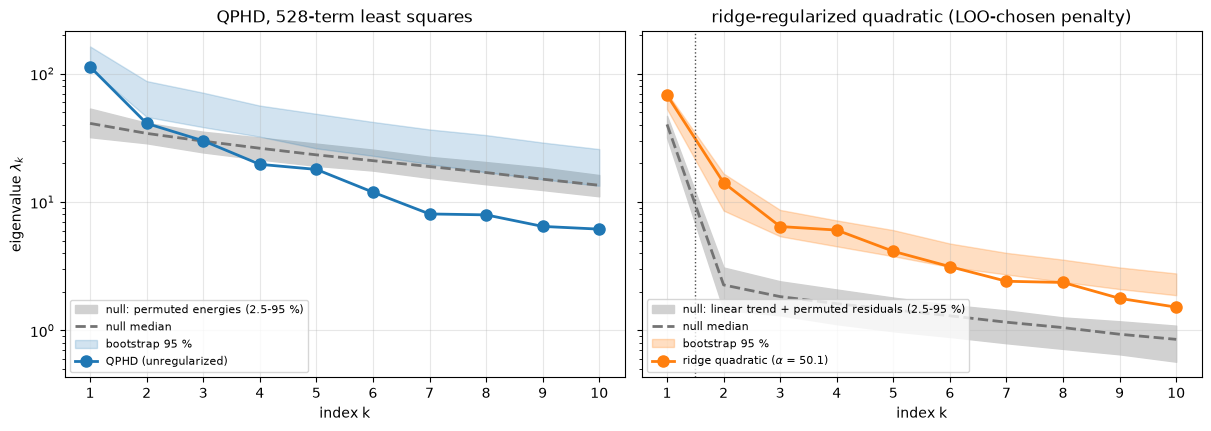

In [9]:
k = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True, constrained_layout=True)
ax = axes[0]
ax.fill_between(k, np.percentile(null_q, 2.5, 0)[:10], nq_95[:10], color='0.82', label='null: permuted energies (2.5-95 %)')
ax.semilogy(k, nq_med[:10], '--', color='0.45', lw=2, label='null median')
blo_q, bhi_q = np.percentile(sub_q.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
ax.fill_between(k, blo_q[:10], bhi_q[:10], color='C0', alpha=0.2, label='bootstrap 95 %')
ax.semilogy(k, lam_q[:10], 'o-', color='C0', lw=2, ms=8, label='QPHD (unregularized)')
ax.set_title('QPHD, 528-term least squares'); ax.set_xlabel('index k'); ax.set_ylabel(r'eigenvalue $\lambda_k$')
ax.legend(fontsize=8, loc='lower left')
ax = axes[1]
ax.fill_between(k, np.percentile(null_l, 2.5, 0)[:10], nl_95[:10], color='0.82', label='null: linear trend + permuted residuals (2.5-95 %)')
ax.semilogy(k, nl_med[:10], '--', color='0.45', lw=2, label='null median')
ax.fill_between(k, blo[:10], bhi[:10], color='C1', alpha=0.25, label='bootstrap 95 %')
ax.semilogy(k, lam[:10], 'o-', color='C1', lw=2, ms=8, label=rf'ridge quadratic ($\alpha$ = {alpha:.1f})')
ax.axvline(sub.n + 0.5, color='0.3', ls=':', lw=1)
ax.set_title('ridge-regularized quadratic (LOO-chosen penalty)'); ax.set_xlabel('index k')
ax.legend(fontsize=8, loc='lower left')
for a in axes:
    a.set_xticks(k); a.grid(alpha=0.3, which='major')
plt.close(fig)
fig

For the ridge quadratic, $\lambda_1 = 68.10$ is 4.81 times $\lambda_2 = 14.145$, and $\lambda_2$ is 2.19 times $\lambda_3 = 6.445$, after which the spectrum decays slowly ($\lambda_3/\lambda_4 = 1.07$); $\lambda_1$ holds a share 0.565 of the trace, of which $\lVert\mathbf g\rVert^2 = 55.2$ and $\operatorname{tr}(\mathbf H\Sigma\mathbf H) = 65.2$. The gap rule picks $n = 1$. The bootstrap ranges ($\lambda_1$ 53.03–70.88, $\lambda_2$ 8.58–16.67, $\lambda_3$ 5.41–8.68) contain the estimates. Under the ridge procedure the permuted energies give eigenvalues near zero (median $\lambda_1 = 2.06\cdot10^{-4}$, 95th percentile 0.444), because the LOO rule then picks a large penalty; so every eigenvalue shown is above pure noise. The stricter reference, one linear direction plus scatter, gives median eigenvalues 40.25, 2.26, 1.83, 1.62 (95th percentiles 46.94, 3.09, 2.41, 2.08) and a median ratio $\lambda_1/\lambda_2 = 17.9$. The observed $\lambda_2 = 14.145$ is far above that null's 3.09: the energy has nonlinear structure beyond one linear trend, and the ratio 4.81 is smaller than a purely one-directional energy would give. On the left, QPHD's $\lambda_2$ to $\lambda_4$ lie inside the permutation band, and its bootstrap band lies above the estimates (a resample repeats points, which the 528-term fit overfits further), so that band is not an uncertainty range for the estimate.

ridge bootstrap mean subspace distance, k = 1..5: [0.162 0.324 0.717 0.657 0.784]
QPHD  bootstrap mean subspace distance, k = 1..5: [0.293 0.715 0.802 0.925 0.928]


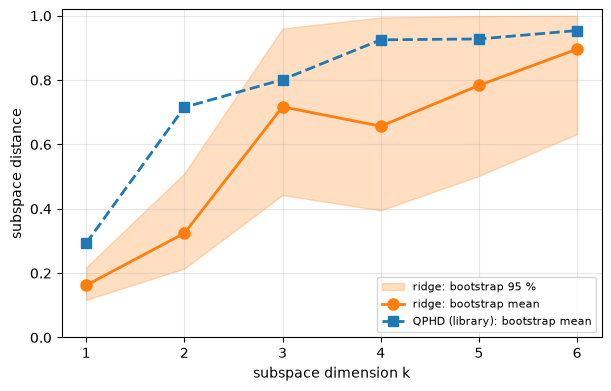

In [10]:
kk = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(6, 3.8), constrained_layout=True)
ax.fill_between(kk, *np.percentile(boot_dist, [2.5, 97.5], axis=0), color='C1', alpha=0.25, label='ridge: bootstrap 95 %')
ax.plot(kk, boot_dist.mean(0), 'o-', color='C1', lw=2, ms=8, label='ridge: bootstrap mean')
ax.plot(kk, sub_q.bootstrap_distances.mean(axis=0)[:6], 's--', color='C0', lw=2, ms=7, label='QPHD (library): bootstrap mean')
ax.set_xlabel('subspace dimension k'); ax.set_ylabel('subspace distance'); ax.set_ylim(0, 1.02); ax.set_xticks(kk)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.close(fig)
print('ridge bootstrap mean subspace distance, k = 1..5:', np.array2string(boot_dist.mean(0)[:5], precision=3))
print('QPHD  bootstrap mean subspace distance, k = 1..5:', np.array2string(sub_q.bootstrap_distances.mean(axis=0)[:5], precision=3))
fig

For the ridge quadratic the bootstrap mean subspace distance is 0.162 for $k = 1$, 0.324 for $k = 2$ and 0.717 or more for $k \ge 3$ (QPHD: 0.293 for $k = 1$ and 0.715 or more for $k \ge 2$). The first direction is well determined; a two-dimensional subspace is moderately determined; no larger one is.

w1: Na AB/PD +0.465, A AB/PD -0.397, CaS AB/PD +0.395, KCa AB/PD -0.378, Na PY +0.238, CaT PY +0.217, CaT AB/PD +0.212, CaS PY +0.180
w2: KCa AB/PD +0.505, CaT PY +0.455, CaS PY +0.301, KCa PY -0.286, A AB/PD +0.221, Na PY +0.197
w1 weight on the 7 synapses: sum of squares 0.059, largest |w1| 0.133
w1 squared weight by neuron: AB/PD 0.720, LP 0.055, PY 0.166
share of the variance of E_total explained by whether AB/PD spikes (eta^2): 0.021; median E_total with AB/PD silent 5.02, spiking 6.78


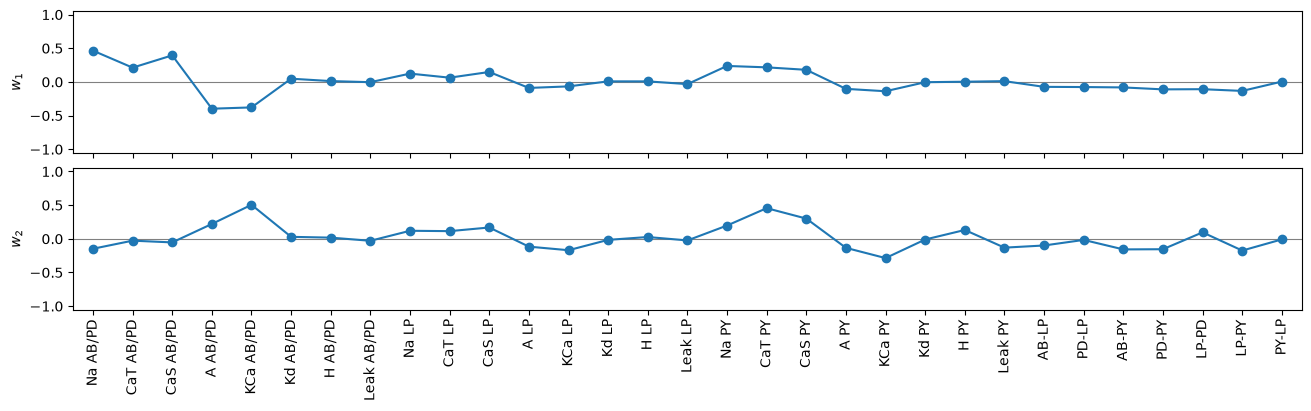

In [11]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(13, 4))
for a in np.atleast_1d(axes):
    a.tick_params(axis='x', labelrotation=90)
plt.close(fig)
top = lambda w, k=6: ', '.join(f'{labels[i]} {w[i]:+.3f}' for i in np.argsort(-np.abs(w))[:k])
print('w1:', top(W[:, 0], 8))
print('w2:', top(W[:, 1], 6))
print(f'w1 weight on the 7 synapses: sum of squares {np.sum(W[syn, 0] ** 2):.3f}, largest |w1| {np.abs(W[syn, 0]).max():.3f}')
print('w1 squared weight by neuron: ' + ', '.join(f'{n} {np.sum(W[8 * j:8 * j + 8, 0] ** 2):.3f}'
                                                  for j, n in enumerate(['AB/PD', 'LP', 'PY'])))
ab = spikes[:, 0] > 0
eta2 = (ab.mean() * (f[ab].mean() - f.mean()) ** 2 + (~ab).mean() * (f[~ab].mean() - f.mean()) ** 2) / f.var()
print(f'share of the variance of E_total explained by whether AB/PD spikes (eta^2): {eta2:.3f}; '
      f'median E_total with AB/PD silent {np.median(f[~ab]):.2f}, spiking {np.median(f[ab]):.2f}')
fig

$\mathbf w_1$ is led by four AB/PD conductances: $+0.465$ on Na, $-0.397$ on A, $+0.395$ on CaS and $-0.378$ on KCa; then come the PY Na ($+0.238$) and CaT ($+0.217$) and the AB/PD CaT ($+0.212$). By neuron, AB/PD carries 0.720 of its squared length, PY 0.166 and LP 0.055; the seven synapses carry 0.059 (largest $|w_1|$ 0.133). Over the prior box the energy grows with the inward Na and Ca conductances and falls with the outward A and KCa conductances, mostly those of AB/PD, which supplies about half of the energy (median share 0.48). Whether AB/PD spikes at all is not the explanation: it accounts for only $\eta^2 = 0.021$ of the variance of the energy (median 5.02 with AB/PD silent, 6.78 with it spiking), so the weights describe how the conductances change the energy within the spiking and silent regimes, not the switch between them; which mechanism that is, this analysis does not show. $\mathbf w_2$ (KCa AB/PD $+0.505$, CaT PY $+0.455$, CaS PY $+0.301$, KCa PY $-0.286$, …) carries an eigenvalue above both nulls, but the two-dimensional subspace is only moderately determined (distance 0.324), so we report it without interpreting it.

y1 range [-1.84, 1.63]; corr(E_total, y1) = 0.6713; rank corr = 0.6720
pyloric-like runs: y1 in [-0.25, 1.18], E_total in [2.88, 19.28]
y1 in (-inf, -0.5]: 201 runs, E_total min 0.026, median 2.39, max 14.17
y1 in (-0.5, 0.5]: 672 runs, E_total min 0.036, median 6.19, max 28.92
y1 in (0.5, inf]: 227 runs, E_total min 0.221, median 16.32, max 48.32
largest y1 with E_total < 0.5: 0.71; corr(residual of a cubic in y1, y2) = 0.093


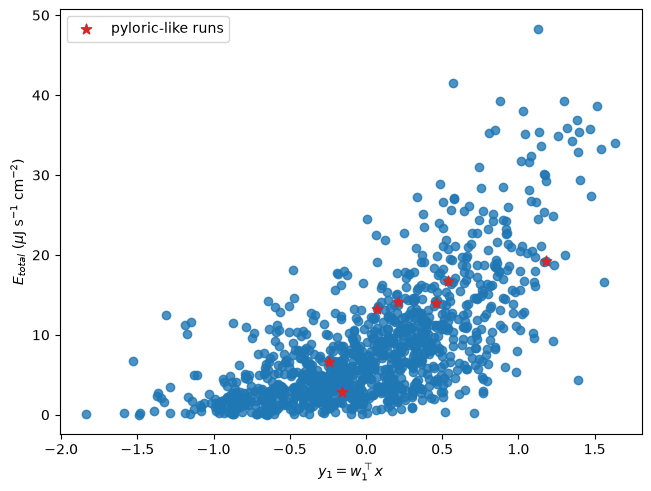

In [12]:
y = Z @ W[:, :2]
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Xa, f=f, dims=1,
                                              qoi_label=r'$E_{total}$ ($\mu$J s$^{-1}$ cm$^{-2}$)')
ax.scatter(y[pyl, 0], f[pyl], s=60, marker='*', color='C3', zorder=3, label='pyloric-like runs')
ax.legend()
plt.close(fig)
rank = lambda v: np.argsort(np.argsort(v))
print(f'y1 range [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; corr(E_total, y1) = {np.corrcoef(f, y[:, 0])[0, 1]:.4f}; '
      f'rank corr = {np.corrcoef(rank(f), rank(y[:, 0]))[0, 1]:.4f}')
print(f'pyloric-like runs: y1 in [{y[pyl, 0].min():.2f}, {y[pyl, 0].max():.2f}], E_total in '
      f'[{f[pyl].min():.2f}, {f[pyl].max():.2f}]')
for a_, b_ in [(-np.inf, -0.5), (-0.5, 0.5), (0.5, np.inf)]:
    k = (y[:, 0] > a_) & (y[:, 0] <= b_)
    print(f'y1 in ({a_}, {b_}]: {k.sum()} runs, E_total min {f[k].min():.3f}, median {np.median(f[k]):.2f}, max {f[k].max():.2f}')
print(f'largest y1 with E_total < 0.5: {y[f < 0.5, 0].max():.2f}; corr(residual of a cubic in y1, y2) = '
      f'{np.corrcoef(f - np.polyval(np.polyfit(y[:, 0], f, 3), y[:, 0]), y[:, 1])[0, 1]:.3f}')
fig

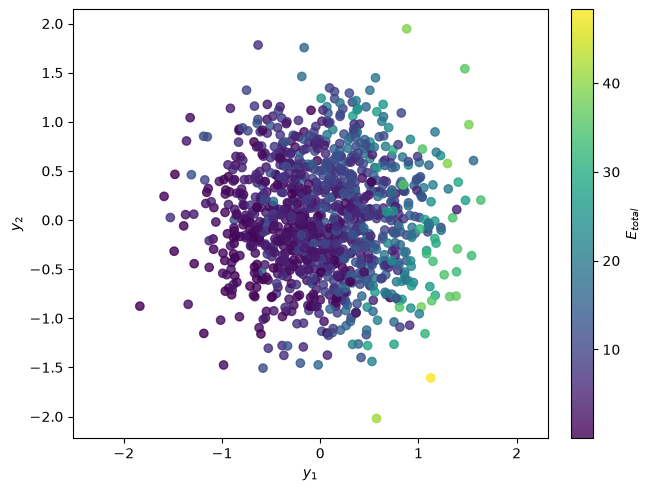

In [13]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Xa, f=f, dims=2, qoi_label=r'$E_{total}$')
plt.close(fig)
fig

Against $y_1 = \mathbf w_1^T\mathbf x$ (range $-1.84$ to $1.63$) the energy has a clear increasing, curved trend with a wide band: correlation 0.6713, rank correlation 0.6720. The median energy rises from 2.39 for $y_1 \le -0.5$ (201 runs) to 6.19 for $-0.5 < y_1 \le 0.5$ (672 runs) and 16.32 for $y_1 > 0.5$ (227 runs), but each band spans more than two orders of magnitude, and energies below 0.5 occur up to $y_1 = 0.71$. The 7 pyloric-like circuits (stars) lie at $y_1$ from $-0.25$ to $1.18$, with energies 2.88–19.28, in the middle of the cloud. In the $(y_1, y_2)$ plot the colour changes mostly along $y_1$; the residual of a cubic in $y_1$ correlates only weakly with $y_2$ (0.093).

LOO R^2: line in y1 0.448; cubic in y1 0.527; quadratic in (y1, y2) 0.611; cubic in (y1, y2) 0.641


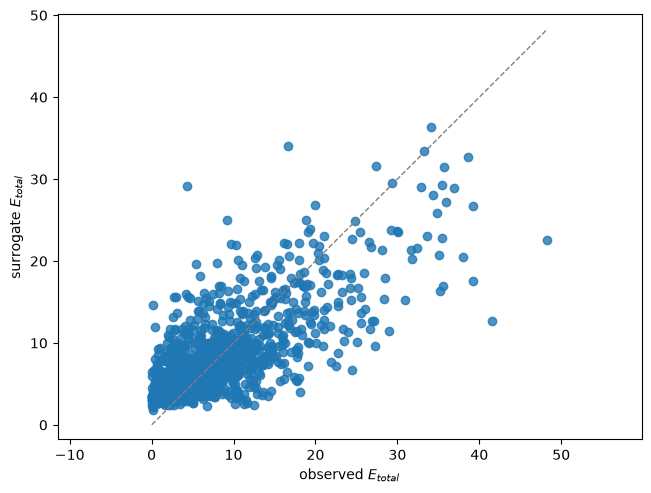

In [14]:
sub2 = ac.with_dimension(sub, 2)
surs = {'line in y1': ac.fit_surrogate(X=Xa, f=f, space=space, subspace=sub, kind='poly', degree=1),
        'cubic in y1': ac.fit_surrogate(X=Xa, f=f, space=space, subspace=sub, kind='poly', degree=3),
        'quadratic in (y1, y2)': ac.fit_surrogate(X=Xa, f=f, space=space, subspace=sub2, kind='poly', degree=2),
        'cubic in (y1, y2)': ac.fit_surrogate(X=Xa, f=f, space=space, subspace=sub2, kind='poly', degree=3)}
print('LOO R^2: ' + '; '.join(f'{k} {s.loo_r_squared:.3f}' for k, s in surs.items()))
fig, ax = ac.plotting.plot_surrogate_fit(surs['cubic in y1'], X=Xa, f=f, qoi_label=r'$E_{total}$')
plt.close(fig)
fig

#### Surrogates on the active variables

A line in $y_1$ has LOO $R^2 = 0.448$, slightly above the full 31-input linear model (0.426), and a cubic in $y_1$ reaches 0.527, about the ridge quadratic in all 31 inputs (0.531): the trend along $\mathbf w_1$ is monotone but curved. Two variables help further (quadratic 0.611, cubic 0.641 in $(y_1, y_2)$), in line with the second eigenvalue above the linear-trend null. These LOO values hold $\mathbf W$ fixed at its estimate from all samples, so they are slightly optimistic. About 40–50 % of the variance of the energy over the prior box is not captured by one or two linear combinations of the conductances.

In [15]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)   # OLS on a uniform space: see text
    ols = ac.active_subspace(space=space, X=Xa, f=f, estimator='ols', n=1, nboot=500, rng=SEED)
a = ols.eigenvectors[:, 0]
print(f'|a . w1| (OLS direction vs ridge w1): {abs(a @ W[:, 0]):.3f}; |w1(QPHD) . w1| = '
      f'{abs(sub_q.eigenvectors[:, 0] @ W[:, 0]):.3f}; OLS bootstrap mean distance (k = 1): '
      f'{ols.bootstrap_distances.mean(axis=0)[0]:.3f}')
_, c_log, loo_log, _ = rq.fit(np.log10(E))
ll, Wl = np.linalg.eigh(grad_matrix(c_log)[0]); ll, Wl = ll[::-1], Wl[:, ::-1]
print(f'ridge quadratic on log10 E_total: LOO R^2 {loo_log:.3f}; lambda_1/lambda_2 = {ll[0] / ll[1]:.2f}, '
      f'lambda_2/lambda_3 = {ll[1] / ll[2]:.2f}; |w1(log) . w1| = {abs(Wl[:, 0] @ W[:, 0]):.3f}')
# Split the design in two halves of 550: QPHD (528 coefficients), ridge (alpha re-chosen on each half) and OLS (32)
idx = np.random.default_rng(SEED).permutation(M)
for est in ('qphd', 'ridge', 'ols'):
    d = []
    for part in (idx[: M // 2], idx[M // 2:]):
        if est == 'ridge':
            d.append(np.linalg.eigh(grad_matrix(RidgeQuadratic(Z[part]).fit(f[part])[1])[0])[1][:, -1])
        else:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ac.ValidityWarning)
                d.append(ac.active_subspace(space=space, X=Xa[part], f=f[part], estimator=est, n=1).eigenvectors[:, 0])
    print(f'{est.upper():5s} on the two halves: |w1(A) . w1| = {abs(d[0] @ W[:, 0]):.3f}, '
          f'|w1(B) . w1| = {abs(d[1] @ W[:, 0]):.3f}, |w1(A) . w1(B)| = {abs(d[0] @ d[1]):.3f}')

|a . w1| (OLS direction vs ridge w1): 0.991; |w1(QPHD) . w1| = 0.992; OLS bootstrap mean distance (k = 1): 0.177
ridge quadratic on log10 E_total: LOO R^2 0.473; lambda_1/lambda_2 = 6.25, lambda_2/lambda_3 = 1.35; |w1(log) . w1| = 0.930


QPHD  on the two halves: |w1(A) . w1| = 0.383, |w1(B) . w1| = 0.243, |w1(A) . w1(B)| = 0.163


RIDGE on the two halves: |w1(A) . w1| = 0.987, |w1(B) . w1| = 0.982, |w1(A) . w1(B)| = 0.947
OLS   on the two halves: |w1(A) . w1| = 0.977, |w1(B) . w1| = 0.967, |w1(A) . w1(B)| = 0.923


**Checks.** The OLS direction $\mathbf a$ (the normalized coefficient vector of the linear model, the paper's own Fig. 4 analysis) is at $|\mathbf a^T\mathbf w_1| = 0.991$ from the ridge direction, and QPHD's first direction at 0.992. The $n = 1$ claim rests on this stable direction and on the subspace distances, not on QPHD's gap: the OLS bootstrap mean distance is 0.177, and on two disjoint halves of 550 samples OLS gives directions at 0.977 and 0.967 from $\mathbf w_1$ (0.923 from each other), the ridge quadratic (with $\alpha$ re-chosen on each half) at 0.987 and 0.982 (0.947 from each other), while QPHD, with 550 samples for 528 coefficients, gives directions at only 0.383 and 0.243. The ridge quadratic on $\log_{10} E_{total}$ gives $\lambda_1/\lambda_2 = 6.25$ and a first direction at 0.930 from $\mathbf w_1$. Simulator noise is small for this purpose: rerunning eight samples with three other noise seeds changes the energy by a median 1.7 % (at most 10 %), about 0.25 % of the variance of the energy over the box (`DATA.md`, Accuracy).

### A restricted region: runs in which all three neurons spike

The paper's region is its posterior, where every circuit bursts like the experimental preparation. The closest region the stored runs allow is the set of runs in which all three neurons spike at least once in the 10 s (row rule: all three spike counts $> 0$). The input density there is no longer uniform (it is the box density conditioned on that event), and with a few hundred runs a 528-term quadratic is not possible, so we use the linear model (OLS, 32 coefficients, $n = 1$) in the same $[-1, 1]$ coordinates, with a bootstrap of its direction. To separate the effect of the region from that of the smaller sample, we compare with OLS on 500 random subsets of the same size drawn from the whole box. The 7 pyloric-like runs are far too few for any estimate.

In [16]:
# Restricted region (stated row rule): the runs in which all three neurons spike in the 10 s
allspk = (spikes > 0).all(axis=1)
rows = np.flatnonzero(allspk); Mr = len(rows)
L1 = np.column_stack([np.ones(M), Z])
def ols_dir(r):
    c = np.linalg.lstsq(L1[r], f[r], rcond=None)[0][1:]; return c / np.linalg.norm(c)
_, loo_r_lin, _ = fit_report(L1[rows], f[rows])
a_r = ols_dir(rows)
a_r = a_r * np.sign(a_r @ a)                     # same orientation as the full-box OLS direction
rng_r = np.random.default_rng(SEED)
boot_r = np.array([abs(a_r @ ols_dir(rng_r.choice(rows, Mr))) for _ in range(500)])
rand = [ols_dir(rng_r.choice(M, Mr, replace=False)) for _ in range(500)]   # random subsets of the same size
share = lambda v: np.array([np.sum(v[8 * j:8 * j + 8] ** 2) for j in range(3)] + [np.sum(v[24:] ** 2)])
print(f'all three neurons spiking: {Mr} of {M} runs; E_total median {np.median(f[rows]):.2f} '
      f'(range {f[rows].min():.2f}-{f[rows].max():.2f})')
print(f'OLS on these {Mr} runs: linear LOO R^2 {loo_r_lin:.3f}; bootstrap |cos| with its own direction: mean '
      f'{boot_r.mean():.3f}, 5th percentile {np.percentile(boot_r, 5):.3f}')
print('restricted-region OLS direction:', top(a_r, 8))
print(f'|cos| with the full-box OLS direction {abs(a_r @ a):.3f}, with the ridge w1 {abs(a_r @ W[:, 0]):.3f}')
cr = np.array([abs(v @ a) for v in rand])
print(f'random subsets of {Mr} runs from the whole box (500): |cos| with the full-box OLS direction median '
      f'{np.median(cr):.3f}, 5th percentile {np.percentile(cr, 5):.3f}')
print('squared weight AB/PD, LP, PY, synapses:  full-box OLS ' + np.array2string(share(a), precision=3)
      + ';  random subsets (median) ' + np.array2string(np.median([share(v) for v in rand], 0), precision=3)
      + ';  all-spiking OLS ' + np.array2string(share(a_r), precision=3))

all three neurons spiking: 277 of 1100 runs; E_total median 7.04 (range 0.93-39.26)
OLS on these 277 runs: linear LOO R^2 0.436; bootstrap |cos| with its own direction: mean 0.952, 5th percentile 0.921
restricted-region OLS direction: CaT PY +0.408, Na PY +0.297, CaS PY +0.296, Na AB/PD +0.275, CaS AB/PD +0.272, A AB/PD -0.253, KCa PY -0.239, CaT AB/PD +0.237
|cos| with the full-box OLS direction 0.862, with the ridge w1 0.816
random subsets of 277 runs from the whole box (500): |cos| with the full-box OLS direction median 0.951, 5th percentile 0.922
squared weight AB/PD, LP, PY, synapses:  full-box OLS [0.64  0.102 0.2   0.058];  random subsets (median) [0.604 0.112 0.198 0.073];  all-spiking OLS [0.284 0.134 0.436 0.146]


All three neurons spike in 277 of the 1100 runs (energy median 7.04, range 0.93–39.26). OLS on them has LOO $R^2 = 0.436$, and its direction is stable (bootstrap mean $|\cos|$ 0.952, 5th percentile 0.921). It is led by **PY**: CaT $+0.408$, Na $+0.297$, CaS $+0.296$, then AB/PD Na $+0.275$ and CaS $+0.272$ and A $-0.253$. Its squared weight is 0.436 on PY and 0.284 on AB/PD, against 0.2 and 0.64 for the full-box OLS direction, and it is at $|\cos| = 0.862$ from that direction. Random subsets of 277 runs from the whole box keep the box weighting (median shares 0.604 AB/PD, 0.198 PY) and stay at median $|\cos|$ 0.951 (5th percentile 0.922) from the full-box direction, so the shift from AB/PD to PY is mostly a region effect, not a small-sample effect: where all three neurons are active, the energy follows PY's inward conductances, as in the paper.

### Comparison with the paper

The paper's Supplementary Fig. 5 computes $\mathbf C$ from the gradients of a neural-network regression of the energy (Eq. 3, p. 18), averaged over its posterior given experimental data, a much narrower region than our prior box, in which the energy spans about 3 to 27 $\mu$J/s (Supp. Fig. 5a axis) and is close to linear (Fig. 4b). Its spectrum (Supp. Fig. 5b) has one dominant eigenvalue; the paper prints no values. The authors' figure notebook (`paper/fig4/notebooks/03_appendix_active_subspace.ipynb` in [github.com/mackelab/stg_energy](https://github.com/mackelab/stg_energy), commit 783d134) prints, in its saved outputs, "Ratio of first two eigenvalues: 35.7893" and "Fraction of first to total: 0.9275". The same notebook calls `sbi`'s `ActiveSubspace.find_directions()` with its defaults, which (in `sbi` 0.16) draw 1000 posterior samples (the saved output shows "Drawing 1000 posterior samples"; the Methods say 10,000) and multiply each gradient entry by the prior's standard deviation in that input; for pyloric's box-uniform prior (uniform in ln of the synapses) that is our $[-1, 1]$ scaling up to one common factor, so the eigenvectors are comparable. Its leading eigenvector (Supp. Fig. 5c) is read below from the figure's pixels; the colours blue, orange, green are AB/PD, LP, PY in the authors' plotting code, which also draws every bar smaller than 0.03 (membrane) or 0.01 (synapses) at that minimum height, so those bars give a sign at most and are counted as "about 0". Signs are compared only where the paper's value exceeds 0.03 in magnitude (20 of 31 components); `SIGN` marks a sign disagreement and `SIZE` an "about 0" component on which the notebook vector exceeds 0.1 in magnitude.

In [17]:
# Supplementary Fig. 5c of the paper, read from the figure's pixels (bar ends, 157 px per unit; colours
# blue, orange, green = AB/PD, LP, PY, the order of stg_energy's plotting code). That code draws any membrane
# bar with |v| < 0.03 at +-0.03 and any synapse bar with |v| < 0.01 at +-0.01, so entries with |v| <= 0.03 give
# a sign at most: they are counted as "about 0" below.
p_fig = np.array([0.21, 0.23, 0.25, -0.16, 0.03, -0.08, -0.02, -0.02,       # AB/PD
                  0.06, 0.06, 0.26, -0.08, 0.03, -0.08, 0.03, -0.025,       # LP
                  0.46, 0.54, 0.31, -0.16, -0.12, -0.08, -0.02, -0.06,      # PY
                  0.05, -0.02, -0.02, 0.10, 0.025, -0.02, 0.11])            # synapses
p_hat = p_fig / np.linalg.norm(p_fig)
big = np.abs(p_fig) > 0.03
vecs = {'ridge w1 (box)': W[:, 0], 'OLS (box)': a, 'OLS (all spiking)': a_r}
print(f"{'component':13s} {'paper':>6s} " + ' '.join(f'{k:>17s}' for k in vecs))
for i in range(m):
    pv = f'{p_fig[i]:+.2f}' if big[i] else '~0'
    marks = []
    for v in vecs.values():
        x = v[i]
        flag = ('' if np.sign(x) == np.sign(p_fig[i]) else ' SIGN') if big[i] else (' SIZE' if abs(x) > 0.1 else '')
        marks.append(f'{x:+.3f}{flag:5s}')
    print(f'{labels[i]:13s} {pv:>6s} ' + ' '.join(f'{s:>17s}' for s in marks))
for k, v in vecs.items():
    agree = int(np.sum(np.sign(v[big]) == np.sign(p_fig[big])))
    print(f'{k:17s}: sign agrees on {agree} of {big.sum()} components with |paper| > 0.03; '
          f'{int(np.sum((~big) & (np.abs(v) > 0.1)))} "about 0" components with |w| > 0.1; |cos| with the paper vector {abs(v @ p_hat):.3f}')
print(f'random subsets of {Mr} box runs (OLS): |cos| with the paper vector median {np.median([abs(v @ p_hat) for v in rand]):.3f}, '
      f'95th percentile {np.percentile([abs(v @ p_hat) for v in rand], 95):.3f}')
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

component      paper    ridge w1 (box)         OLS (box) OLS (all spiking)
Na AB/PD       +0.21       +0.465            +0.459            +0.275     
CaT AB/PD      +0.23       +0.212            +0.226            +0.237     
CaS AB/PD      +0.25       +0.395            +0.382            +0.272     
A AB/PD        -0.16       -0.397            -0.360            -0.253     
KCa AB/PD         ~0       -0.378 SIZE       -0.317 SIZE       -0.039     
Kd AB/PD       -0.08       +0.048 SIGN       +0.042 SIGN       +0.094 SIGN
H AB/PD           ~0       +0.013            +0.023            +0.060     
Leak AB/PD        ~0       -0.004            +0.002            -0.014     
Na LP          +0.06       +0.124            +0.173            +0.230     
CaT LP         +0.06       +0.063            +0.080            +0.034     
CaS LP         +0.26       +0.148            +0.201            +0.169     
A LP           -0.08       -0.089            -0.103            -0.021     
KCa LP            ~0     

| quantity | paper (posterior, NN-regression gradients) | notebook (prior box, ridge quadratic; restricted region, OLS) |
|---|---|---|
| region | posterior samples (10,000 in the Methods, p. 18; 1000 in the authors' notebook) | 1100 uniform samples of the prior box; 277 of them with all three neurons spiking |
| fraction of prior circuits with defined rhythm features | 0.97 % "valid" of 3 million (p. 18); "99 % do not produce spikes or bursts" (p. 4) | 0.64 % pyloric-like (7 of 1100); 25.2 % with all three neurons spiking |
| eigenvalue ratio $\lambda_1/\lambda_2$ | not printed in the paper (one dominant eigenvalue, Supp. Fig. 5b); 35.79 in the authors' notebook output | 4.81 (ridge quadratic; $\lambda_2$ above the one-direction null); QPHD's 2.76 is against its noise floor and not used |
| share of the trace in $\lambda_1$ | 0.9275 (authors' notebook output) | 0.565 (ridge quadratic) |
| sign of $\mathbf w_1$ on Na, CaT, CaS | positive in all three neurons (Supp. Fig. 5c) | positive in all three neurons (9 of 9), box and restricted region |
| sign of $\mathbf w_1$ on A | negative in all three neurons | negative in all three neurons |
| sign of $\mathbf w_1$ on Kd | negative, about $-0.08$ in all three neurons | AB/PD $+0.048$ and LP $+0.009$ (disagree), PY $-0.004$ (about 0) |
| AB/PD KCa | about 0 (bar at the 0.03 minimum height) | $-0.378$ (box); $-0.039$ (restricted region) |
| PY leak | about $-0.06$ | $+0.012$ (disagree); $-0.087$ (restricted region) |
| synapses | small; positive on PD→PY (about $+0.10$), PY→LP (about $+0.11$) and AB→LP (about $+0.05$); 0.08 % of the energy (p. 7) | squared weight 0.059 in total; PD→PY $-0.110$ and AB→LP $-0.073$ (disagree), PY→LP $+0.005$; LP→PD $-0.108$ and LP→PY $-0.133$ where the paper is about 0. The synaptic energy is included in $E_{total}$ but not computed separately |
| largest components of $\mathbf w_1$ | PY CaT and Na (about 0.54 and 0.46) | box: AB/PD Na $+0.465$, A $-0.397$, CaS $+0.395$, KCa $-0.378$; restricted region: PY CaT $+0.408$, Na $+0.297$, CaS $+0.296$ |
| sign agreement where the paper's $|w| > 0.03$ | — | 15 of 20 (ridge, box); 14 of 20 (OLS, box); 15 of 20 (OLS, restricted region) |
| $|\cos|$ with the paper's vector (by eye) | — | 0.666 (ridge, box); 0.709 (OLS, box); 0.753 (OLS, restricted region; random box subsets of the same size: median 0.674, 95th percentile 0.749) |
| linear predictability of the energy | "accurately" linear (Fig. 4b; $R^2$ not reported) | linear LOO $R^2 = 0.426$ (box), 0.436 (restricted region); cubic in $y_1$ 0.527 |
| energy range ($\mu$J s$^{-1}$ cm$^{-2}$) | about 3–27 for posterior circuits (Supp. Fig. 5a) | 0.026–48.32; 0.93–39.26 with all three neurons spiking; 2.88–19.28 for the 7 pyloric-like circuits |

The signs agree on Na, CaT, CaS and A in all three neurons, in both regions: the energy grows with the inward Na and Ca conductances and falls with A. They do not agree everywhere. The paper's Kd is about $-0.08$ in all three neurons, as large as LP's A, while the notebook's is positive in AB/PD and LP and about 0 in PY. The paper's AB/PD KCa is about 0, while the box direction has $-0.378$; the restricted region brings it to $-0.039$. On the synapses, the paper's PD→PY and AB→LP weights are positive and the notebook's negative, its PY→LP weight is positive (about $+0.11$) and the notebook's about 0 in the box ($+0.005$) and negative in the restricted region ($-0.153$), and LP→PD and LP→PY carry about $-0.1$ in the notebook where the paper's are about 0. The weighting depends on the region: over the box the pacemaker AB/PD dominates, while on the runs where all three neurons spike PY leads as in the paper, and the restricted-region direction is closer to the paper's (0.753) than the box directions are. Part of the remaining difference is the estimator and part the region: the paper's single dominant eigenvalue ($\lambda_1/\lambda_2 = 35.79$ in the authors' output) is much sharper than the box's 4.81, whose $\lambda_2$ reflects nonlinear structure over the box. Reproducing Supp. Fig. 5 needs the authors' 35,939-circuit database, which is on the Hugging Face Hub (`DATA.md`) and was not reachable when this notebook was built.

### References

[1] M. Deistler, J. H. Macke, P. J. Gonçalves. Energy-efficient network activity from disparate circuit parameters. *Proceedings of the National Academy of Sciences* 119(44):e2207632119, 2022. [doi:10.1073/pnas.2207632119](https://doi.org/10.1073/pnas.2207632119). Preprint read for this notebook: bioRxiv, [doi:10.1101/2021.07.30.454484](https://doi.org/10.1101/2021.07.30.454484).

[2] A. A. Prinz, D. Bucher, E. Marder. Similar network activity from disparate circuit parameters. *Nature Neuroscience* 7(12):1345–1352, 2004. [doi:10.1038/nn1352](https://doi.org/10.1038/nn1352).

[3] A. Moujahid, A. d'Anjou, F. J. Torrealdea, F. Torrealdea. Energy and information in Hodgkin-Huxley neurons. *Physical Review E* 83(3):031912, 2011. [doi:10.1103/PhysRevE.83.031912](https://doi.org/10.1103/PhysRevE.83.031912).

[4] P. J. Gonçalves, J.-M. Lueckmann, M. Deistler, M. Nonnenmacher, K. Öcal, G. Bassetto, C. Chintaluri, W. F. Podlaski, S. A. Haddad, T. P. Vogels, D. S. Greenberg, J. H. Macke. Training deep neural density estimators to identify mechanistic models of neural dynamics. *eLife* 9:e56261, 2020. [doi:10.7554/eLife.56261](https://doi.org/10.7554/eLife.56261).

[5] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

[6] K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258).

Simulator: M. Deistler and mackelab, pyloric, https://github.com/mackelab/pyloric (MIT licence), commit 89dd27d769fa2652d21bca1dbbc098c85e40244a.

Code, figure notebooks and data of [1]: https://github.com/mackelab/stg_energy (commit 783d1342d032a99c99a5c477e3a3a3b921cc8432; read, not run) and the Hugging Face dataset https://huggingface.co/datasets/mackelab/STG_energy (not used). Sensitivity analysis: `sbi` `ActiveSubspace`, https://github.com/mackelab/sbi (v0.16.0 read).

### Acknowledgments

From [[1]](https://doi.org/10.1073/pnas.2207632119) (preprint, p. 13–14): the work was supported by the German Research Foundation (DFG) through SFB 1089 "Synaptic Microcircuits" and Germany's Excellence Strategy, EXC-Number 2064/1, Project number 390727645, and by the German Federal Ministry of Education and Research (BMBF, project "ADIMEM", FKZ 01IS18052 A-D); the International Max Planck Research School for Intelligent Systems (IMPRS-IS) supported M. Deistler. The published version's Crossref record also lists BMBF award 01IS18039A. The authors thank S. A. Haddad and E. Marder for sharing their data.